#### Importando bibliotecas necessárias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from scipy.stats import linregress
import sys

#### Definindo configurações iniciais

In [ ]:
#definindo caminho para o arquivo de funções
sys.path.insert(0, "scripts")

#importando funções do script funcoes.py
from funcoes import (
    carregar_dados,
    preparar_datas,
    agrupar_por_UA
)


#### Rodar os dados e fazer uma primeira visualização geral

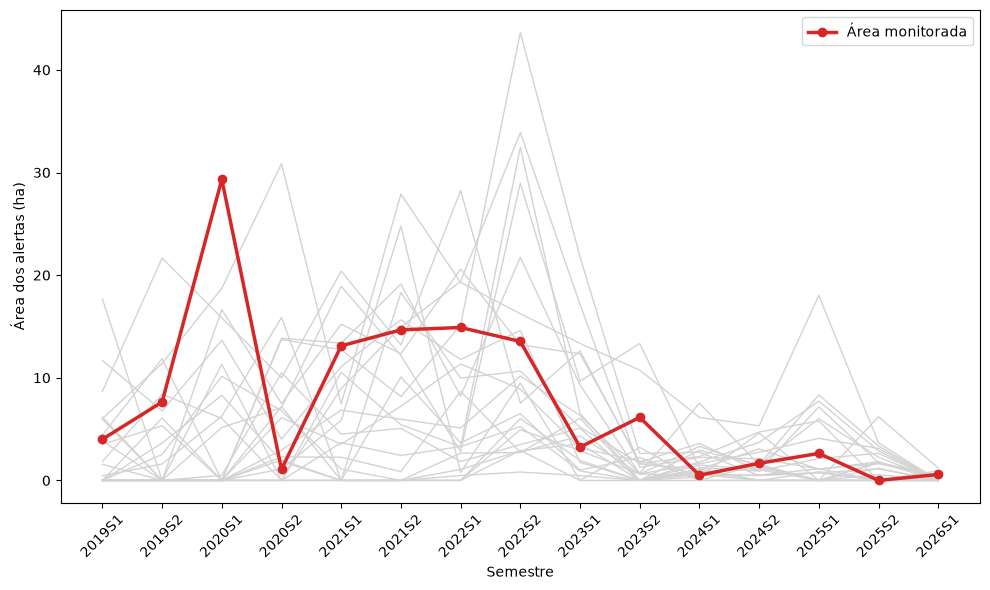

In [ ]:
#carregando e preparando os dados
alertas_UAs = carregar_dados("data/alertas_UAs.csv")
alertas_UAs = preparar_datas(alertas_UAs)
tabela = agrupar_por_UA(alertas_UAs, operacao="sum") #não preciso definir o resto pq estou usando default (escala por semestre)

# Criar uma figura pra colocar meu gráfico
fig, ax = plt.subplots(figsize=(10, 6))
# Todas as UAs em cinza claro, sem destaque
for uid in tabela.columns:
    if uid != 50:
        ax.plot(tabela.index.astype(str), tabela[uid], color="lightgray", linewidth=1)

# UA 50 em destaque para alertas_UAs e 25 para alertas_UAs2
ax.plot(tabela.index.astype(str), tabela[50], color="tab:red", linewidth=2.5, marker="o", label="Área monitorada")

ax.set_xlabel("Semestre")
ax.set_ylabel("Área dos alertas (ha)")
#ax.set_title("Área detectada por semestre — destaque id_UA 25")
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

#### Filtrando e calculando dados

In [66]:
# Filtra os dados a partir de 2022S2 (usando os dados originais, antes de agrupar)
alertas_UAs_filtrado = alertas_UAs[
    (alertas_UAs["SEMESTRE"] >= "2022S2") &
    (alertas_UAs["SEMESTRE"] <= "2025S2")
]
# Agrupa por semestre e id_UA, igual antes, mas só com os dados filtrados
tabela_filtrada = agrupar_por_UA(alertas_UAs_filtrado, operacao="sum")

# Calcula a declividade (slope) pra cada id_UA
## começa criando um dicionario vazio
declividades = {}
## agora preenche o dicionario com loop for
for uid in tabela_filtrada.columns:
    y = tabela_filtrada[uid].fillna(0).values
    x = np.arange(len(y))  # 0, 1, 2, 3... representando cada semestre
    #decupando a função de estatisticas da regressao linear:
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    #preenchendo o dicionario com a declividade de cada id_UA
    declividades[uid] = slope

declividades = pd.Series(declividades, name="declividade")
# print(declividades.sort_values(ascending=False))

media = declividades.mean()
desvio = declividades.std()
zscore_50 = (declividades[50] - media) / desvio

#### Gerando o gráfico final

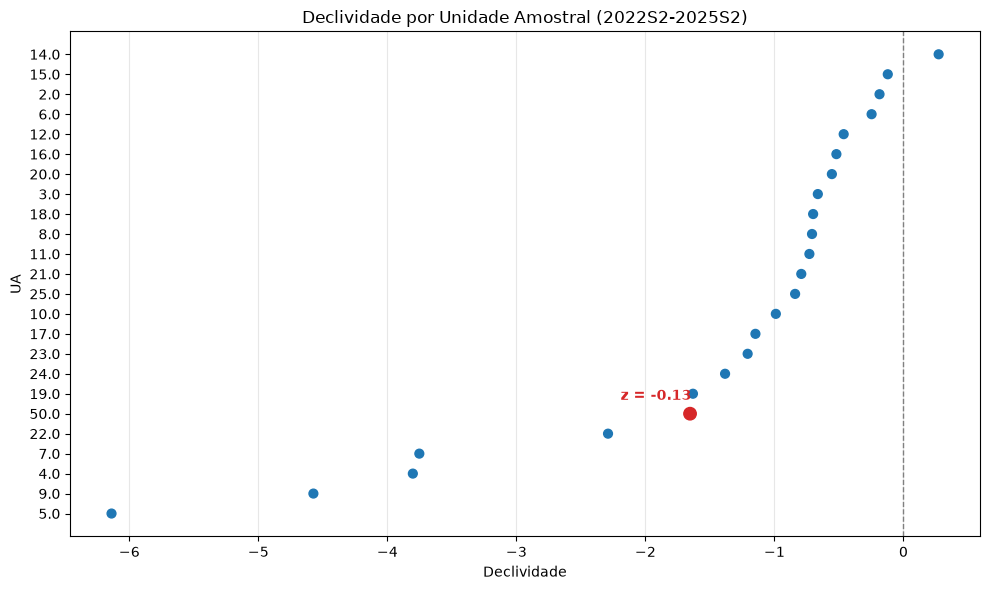

In [67]:
### DUAS MANEIRAS DE PLOTAR MEUS RESULTADOS então criei uma função e eu escolho qual chamar
def plotar_declividade(declividades, tipo, bins=10):
    if tipo == "reta":
        declividades_ordenadas = declividades.sort_values()
        cores = ["tab:red" if uid == 50 else "tab:blue" for uid in declividades_ordenadas.index]
        tamanhos = [80 if uid == 50 else 40 for uid in declividades_ordenadas.index]
        
        fig, ax = plt.subplots(figsize=(10, 6))
        ax.scatter(declividades_ordenadas.values, range(len(declividades_ordenadas)), color=cores, s=tamanhos, zorder=3)
        
        ax.set_yticks(range(len(declividades_ordenadas)))
        ax.set_yticklabels(declividades_ordenadas.index)
        ax.set_xlabel("Declividade")
        ax.set_ylabel("UA")
        ax.set_title("Declividade por Unidade Amostral (2022S2-2025S2)")
        ax.axvline(x=0, color="gray", linestyle="--", linewidth=1)
        ax.grid(axis="x", alpha=0.3)
        
        # Calcula e anota o z-score do 50
        media = declividades.mean()
        desvio = declividades.std()
        zscore = (declividades[50] - media) / desvio
        
        posicao_y = list(declividades_ordenadas.index).index(50)
        posicao_x = declividades_ordenadas[50]
        
        ax.annotate(f"z = {zscore:.2f}",
                     xy=(posicao_x, posicao_y),
                     xytext=(-50, 10), textcoords="offset points",
                     fontsize=10, color="tab:red", fontweight="bold")
        
        plt.tight_layout()
        plt.show()

    elif tipo == "histograma":
        valores = declividades.values
        ids = declividades.index
        limites = np.linspace(valores.min(), valores.max(), bins+1)
        bin_indices = np.digitize(valores, limites)
        centros = (limites[:-1] + limites[1:]) / 2

        fig, ax = plt.subplots(figsize=(10, 6))
        contador_bin = {}
        
        for uid, valor, bin_idx in zip(ids, valores, bin_indices):
            altura = contador_bin.get(bin_idx, 0)
            cor = "tab:red" if uid == 50 else "tab:blue"
            tamanho = 100 if uid == 50 else 60
            x_centro = centros[min(bin_idx, len(centros) - 1)]  # posição X = centro da faixa

            ax.scatter(x_centro, altura, color=cor, s=tamanho, zorder=3)
            contador_bin[bin_idx] = altura + 1
        
        ax.set_xlabel("Declividade")
        ax.set_ylabel("Contagem")
        ax.set_title("Distribuição da declividade")
        ax.axvline(x=0, color="gray", linestyle="--", linewidth=1)
        plt.tight_layout()
        plt.show()

    else: raise ValueError("tipo deve ser 'reta' ou 'histograma'")

plot_declividades = plotar_declividade(declividades, tipo="reta")